# IND320 Project work 2

**Author:** Inge Gilje Gunnarshaug

## 1. Introduction

This is the notebook for the second assignment in IND320. The corresponding streamlit app and github repository can be found here:

### Project links

- **GitHub repository:** https://github.com/IngeGiljeGunnarshaug/ind320-inge-gilje-gunnarshaug
- **Streamlit app:** https://ind320-inge-gilje-gunnarshaug-task2.streamlit.app/

## 2. Environment and Imports

This notebook uses Pandas for data processing, Matplotlib for visualization, and Requests for retrieving data from the NVE and ENTSO-E APIs.

Apache Spark (PySpark) is used to process and transfer electricity flow data to and from Apache Cassandra. The processed data is then stored in MongoDB Atlas for use in the Streamlit application.

Environment variables are used to securely manage API tokens and database credentials.

The required packages and tested versions are documented in the repository.

In [98]:
from cassandra.cluster import Cluster
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

import xml.etree.ElementTree as ET

import os
from dotenv import load_dotenv
from pymongo import MongoClient, UpdateOne

import requests
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline

## 3. Connection tests


Quick test to initialize all relevant connections.

### 3.1 Cassandra

In [66]:
cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect()

# Create keyspace if it doesn't exist
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH replication = {
        'class': 'SimpleStrategy',
        'replication_factor': 1
    }
""")

session.set_keyspace("ind320")

print("Connected to Cassandra")

Connected to Cassandra


### 3.2 Spark

In [68]:
spark = (
    SparkSession.builder
    .appName("IND320_Assignment2")
    .master("local[*]")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.1


### 3.3 Spark and Cassandra

In [69]:
# Verify Cassandra
session.execute("SELECT release_version FROM system.local").one()
print("Cassandra connection: OK")

# Verify Spark
spark.range(5).show()
print("Spark connection: OK")

Cassandra connection: OK
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+

Spark connection: OK


## 4. Magasinstatistikk API

### 4.1 Load data & Preprocessing

In [ ]:
# Loading in the data from NVE´s API using request
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=60)
response.raise_for_status()

data = response.json()

print("Type:", type(data))
print("Antall elementer:", len(data))
print("Første element:", data[0])

Type: <class 'list'>
Antall elementer: 14922
Første element: {'dato_Id': '1995-09-03', 'omrType': 'EL', 'omrnr': 4, 'iso_aar': 1995, 'iso_uke': 35, 'fyllingsgrad': 0.94472134, 'kapasitet_TWh': 21.079208, 'fylling_TWh': 19.913979, 'neste_Publiseringsdato': '0001-01-01T00:00:00', 'fyllingsgrad_forrige_uke': 0.9368882, 'endring_fyllingsgrad': 0.007833123}


Performing the exact same preprocessing as in assignment 1 to replicate the plots:

In [ ]:
raw_df = pd.DataFrame(data)

# Use descriptive names and retain units in the energy-column names.
column_mapping = {
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_fraction",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "stored_energy_twh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "previous_week_fill_fraction",
    "endring_fyllingsgrad": "fill_fraction_change",
}

# Work on a separate DataFrame, keeping raw_df unchanged.
df = raw_df.rename(columns=column_mapping).copy()

df["date"] = pd.to_datetime(
    df["date"],
    format="%Y-%m-%d",
    errors="raise",
)

publication_text = df["next_publication_date"].astype("string")
placeholder_mask = publication_text.eq("0001-01-01T00:00:00").fillna(False)

df["next_publication_date"] = pd.to_datetime(
    publication_text.mask(placeholder_mask),
    format="%Y-%m-%dT%H:%M:%S",
    errors="raise",
)

df = (
    df.sort_values(["area_type", "area_number", "date"])
    .reset_index(drop=True)
)

# Only these columns represent reservoir measurements.
measurement_columns = [
    "fill_fraction",
    "capacity_twh",
    "stored_energy_twh",
    "previous_week_fill_fraction",
    "fill_fraction_change",
]

metadata_columns = [
    "date",
    "area_type",
    "area_number",
    "iso_year",
    "iso_week",
    "next_publication_date",
]

# Validate that measurement values are numeric; unexpected text raises an error.
df[measurement_columns] = df[measurement_columns].apply(
    pd.to_numeric,
    errors="raise",
)

# Use these labels and multipliers in later plots.
# The underlying DataFrame retains the original fractions.
plot_settings = {
    "fill_fraction": {
        "label": "Reservoir fill (%)",
        "multiplier": 100,
    },
    "capacity_twh": {
        "label": "Reservoir capacity (TWh)",
        "multiplier": 1,
    },
    "stored_energy_twh": {
        "label": "Stored energy (TWh)",
        "multiplier": 1,
    },
    "previous_week_fill_fraction": {
        "label": "Previous week's fill (%)",
        "multiplier": 100,
    },
    "fill_fraction_change": {
        "label": "Weekly fill change (percentage points)",
        "multiplier": 100,
    },
}

# Choose a type-number combination from the area summary in section 3.4.
SELECTED_AREA_TYPE = "NO"
SELECTED_AREA_NUMBER = 0

# Filter using both identifiers to avoid mixing different area definitions.
area_mask = (
    df["area_type"].eq(SELECTED_AREA_TYPE)
    & df["area_number"].eq(SELECTED_AREA_NUMBER)
)

area_df = (
    df.loc[area_mask]
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

if area_df.empty:
    raise ValueError("The selected area has no observations. Check section 3.4.")

area_label = f"{SELECTED_AREA_TYPE} — area {SELECTED_AREA_NUMBER}"

### 4.2 Corresponding plots from Assignment 1

#### Numerical features

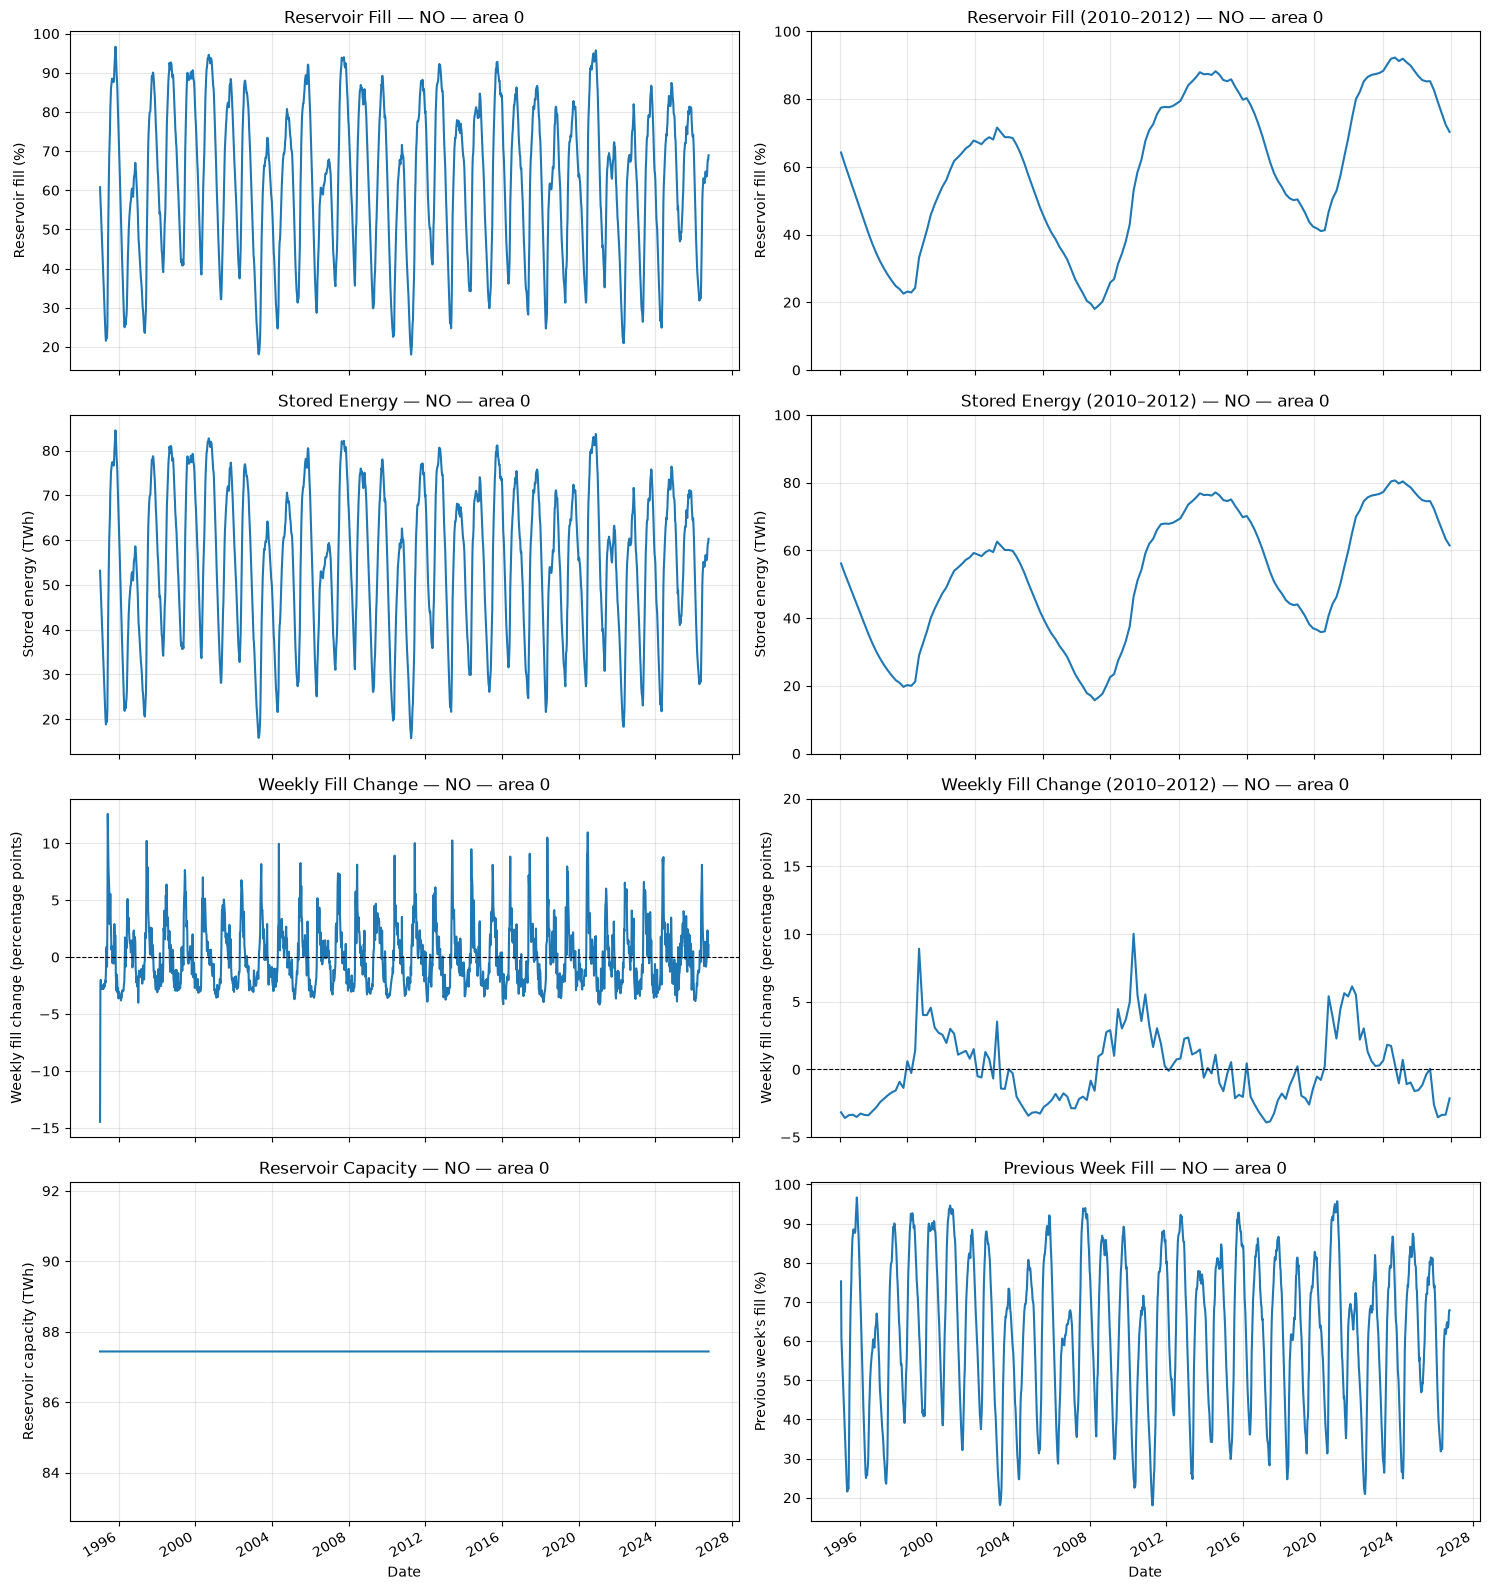

In [ ]:
# Select the three-year period
start_year = 2010
end_year = start_year + 2

three_years = area_df.loc[
    area_df["date"].ge(f"{start_year}-01-01")
    & area_df["date"].lt(f"{end_year + 1}-01-01")
].sort_values("date")

if three_years.empty:
    raise ValueError("No observations available for the selected years.")

# Plot configuration:
# (column, dataset, title, multiplier, y-limits)
plots = [
    # Row 1: Reservoir Fill
    ("fill_fraction", area_df, "Reservoir Fill", None, None),
    ("fill_fraction", three_years, f"Reservoir Fill ({start_year}–{end_year})", 100, (0, 100)),

    # Row 2: Stored Energy
    ("stored_energy_twh", area_df, "Stored Energy", None, None),
    ("stored_energy_twh", three_years, f"Stored Energy ({start_year}–{end_year})", 1, (0, 100)),

    # Row 3: Weekly Fill Change
    ("fill_fraction_change", area_df, "Weekly Fill Change", None, None),
    ("fill_fraction_change", three_years, f"Weekly Fill Change ({start_year}–{end_year})", 100, (-5, 20)),

    # Row 4: Measurements with only full history
    ("capacity_twh", area_df, "Reservoir Capacity", None, None),
    ("previous_week_fill_fraction", area_df, "Previous Week Fill", None, None),
]

# Create 4 rows × 2 columns
fig, axes = plt.subplots(4, 2, figsize=(15, 16))

for ax, (column, data, title, multiplier, ylim) in zip(axes.flat, plots):

    settings = plot_settings[column]

    # Apply display conversion without modifying original data
    scale = settings["multiplier"] if multiplier is None else multiplier
    values = data[column] * scale

    ax.plot(data["date"], values, linewidth=1.5)

    ax.set_title(f"{title} — {area_label}")
    ax.set_xlabel("Date")
    ax.set_ylabel(settings["label"])

    if ylim is not None:
        ax.set_ylim(*ylim)

    if column == "fill_fraction_change":
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

    ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

#### Categorical features

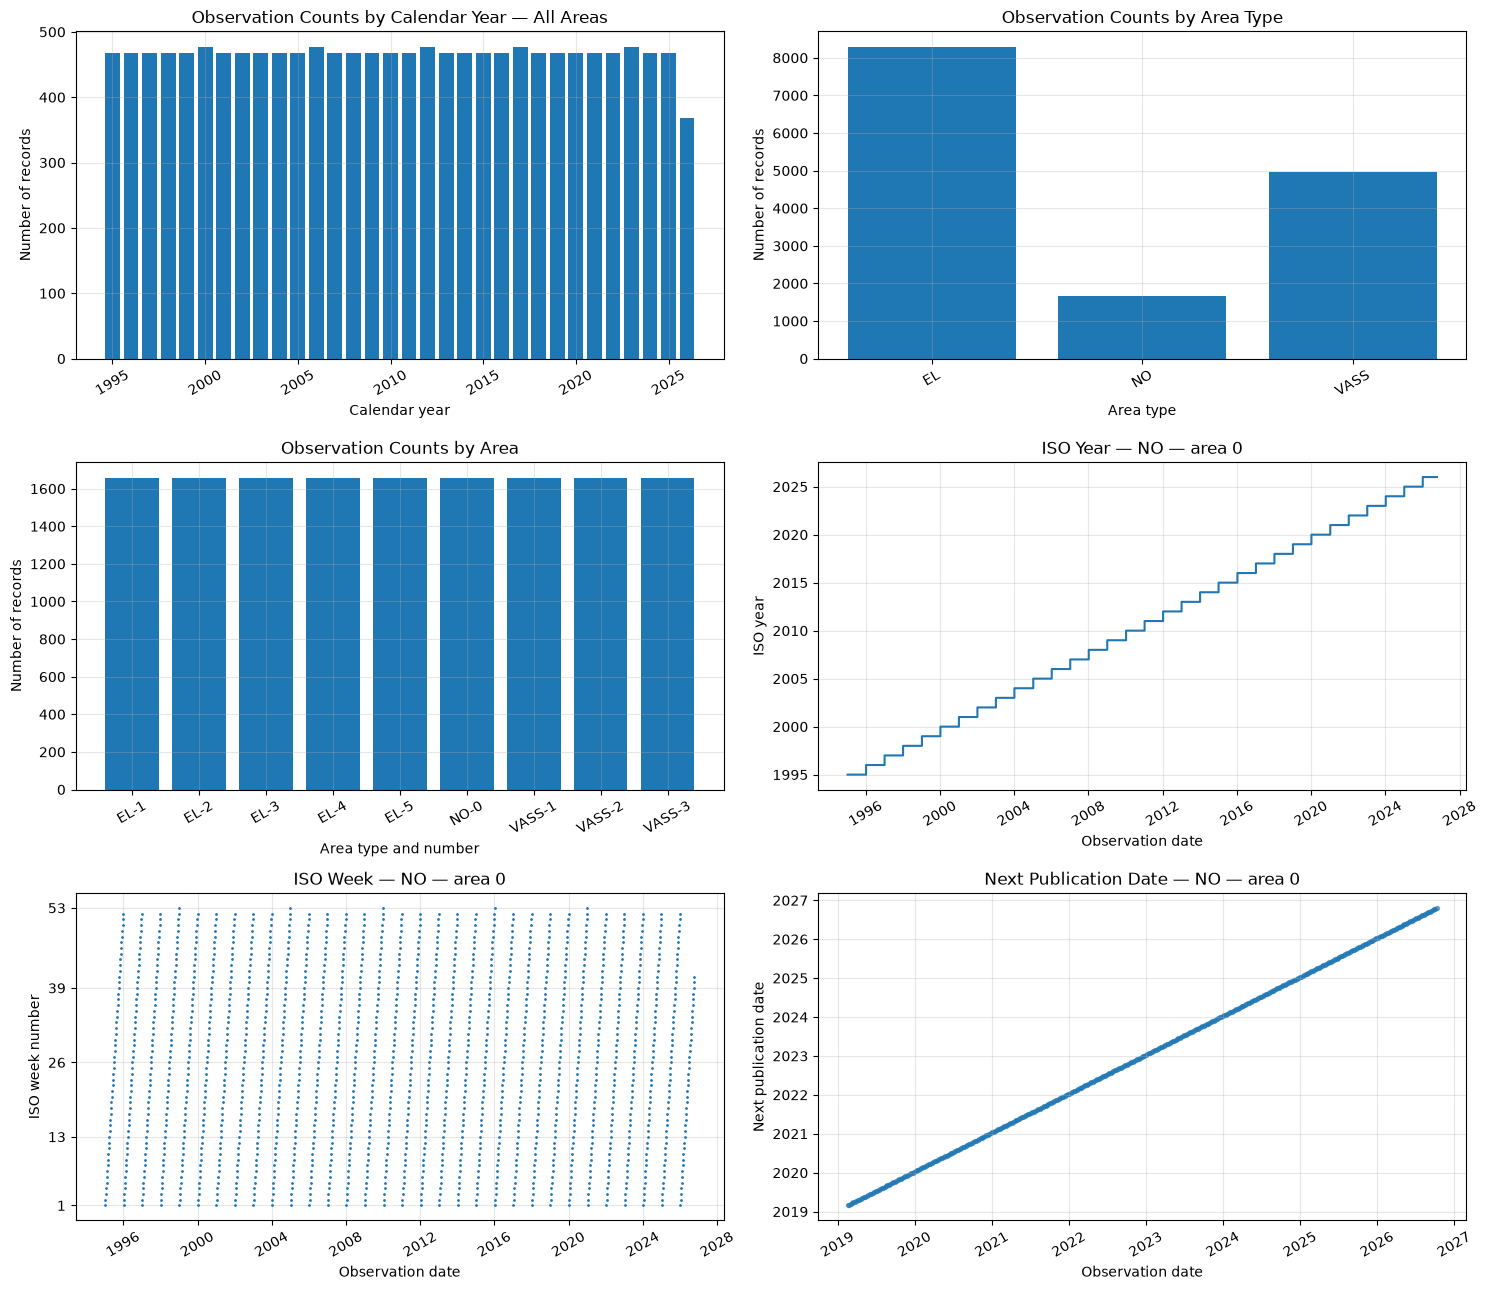

In [ ]:
# Prepare data
observations_per_year = df.groupby(df["date"].dt.year).size().sort_index()

area_type_counts = df["area_type"].value_counts().sort_index()

area_counts = (
    df.groupby(["area_type", "area_number"])
    .size()
    .sort_index()
)

area_labels = [
    f"{area_type}-{area_number}"
    for area_type, area_number in area_counts.index
]

publication_df = area_df.dropna(subset=["next_publication_date"])

# Create 3 rows × 2 columns
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

# 1. Observations by calendar year
ax = axes[0]
ax.bar(observations_per_year.index, observations_per_year.values)
ax.set_title("Observation Counts by Calendar Year — All Areas")
ax.set_xlabel("Calendar year")
ax.set_ylabel("Number of records")

# 2. Observations by area type
ax = axes[1]
ax.bar(area_type_counts.index, area_type_counts.values)
ax.set_title("Observation Counts by Area Type")
ax.set_xlabel("Area type")
ax.set_ylabel("Number of records")

# 3. Observations by area
ax = axes[2]
ax.bar(area_labels, area_counts.values)
ax.set_title("Observation Counts by Area")
ax.set_xlabel("Area type and number")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=45)

# 4. ISO year
ax = axes[3]
ax.step(area_df["date"], area_df["iso_year"], where="post")
ax.set_title(f"ISO Year — {area_label}")
ax.set_xlabel("Observation date")
ax.set_ylabel("ISO year")

# 5. ISO week
ax = axes[4]
ax.plot(
    area_df["date"],
    area_df["iso_week"],
    linestyle="none",
    marker=".",
    markersize=2,
)
ax.set_title(f"ISO Week — {area_label}")
ax.set_xlabel("Observation date")
ax.set_ylabel("ISO week number")
ax.set_yticks([1, 13, 26, 39, 53])

# 6. Next publication date
ax = axes[5]

if not publication_df.empty:
    ax.scatter(
        publication_df["date"],
        publication_df["next_publication_date"],
        s=8,
        alpha=0.6,
    )
    ax.xaxis_date()
    ax.yaxis_date()
else:
    ax.text(
        0.5, 0.5,
        "No valid publication dates available",
        ha="center", va="center",
        transform=ax.transAxes,
    )

ax.set_title(f"Next Publication Date — {area_label}")
ax.set_xlabel("Observation date")
ax.set_ylabel("Next publication date")

# Apply consistent formatting
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", labelrotation=30)

fig.tight_layout()
plt.show()

#### Combined plot

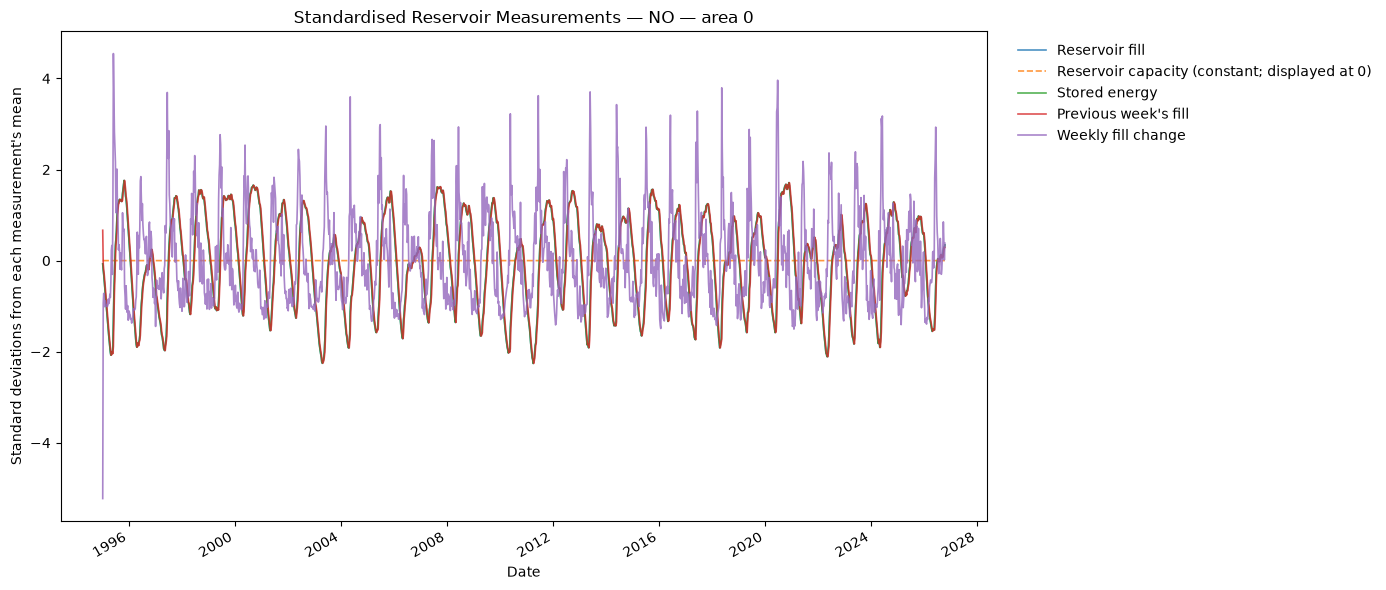

In [43]:
# Select the reservoir measurements, keeping dates as the index.
measurements = (
    area_df.set_index("date")[measurement_columns]
    .sort_index()
)

# Calculate each measurement's mean and sample standard deviation.
means = measurements.mean()
standard_deviations = measurements.std(ddof=1)

# Identify constant columns directly to avoid floating-point rounding issues.
constant_mask = measurements.nunique(dropna=True).eq(1)

# Undefined or zero standard deviations cannot be used as divisors.
safe_std = standard_deviations.mask(
    constant_mask | standard_deviations.eq(0)
)

standardised_df = (measurements - means) / safe_std

# Constant columns have no defined z-score.
# Display their observed values at zero by convention; preserve missing values.
for column in measurements.columns[constant_mask]:
    standardised_df[column] = measurements[column].where(
        measurements[column].isna(),
        0.0,
    )

# Document the parameters and treatment used for each measurement.
scaling_summary = pd.DataFrame({
    "mean_original_units": means,
    "std_original_units": standard_deviations,
    "constant": constant_mask,
    "treatment": [
        "Displayed at zero (constant)"
        if constant_mask[column]
        else (
            "Not plotted (insufficient data)"
            if pd.isna(safe_std[column])
            else "Standardised"
        )
        for column in measurements.columns
    ],
})

# Labels omit original units because the plotted values are standardised.
series_labels = {
    "fill_fraction": "Reservoir fill",
    "capacity_twh": "Reservoir capacity",
    "stored_energy_twh": "Stored energy",
    "previous_week_fill_fraction": "Previous week's fill",
    "fill_fraction_change": "Weekly fill change",
}

fig, ax = plt.subplots(figsize=(14, 6))

for column in measurement_columns:
    # Skip columns without any values that can be displayed.
    if standardised_df[column].notna().sum() == 0:
        continue

    is_constant = constant_mask[column]
    label = series_labels[column]

    if is_constant:
        label += " (constant; displayed at 0)"

    ax.plot(
        standardised_df.index,
        standardised_df[column],
        label=label,
        linestyle="--" if is_constant else "-",
        linewidth=1.2,
        alpha=0.8,
    )

ax.set_title(f"Standardised Reservoir Measurements — {area_label}")
ax.set_xlabel("Date")
ax.set_ylabel("Standard deviations from each measurement's mean")

# Position the legend outside the plotting area to avoid obscuring the lines.
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 5. ENTSO-E API data
### 5.1 Download data

In [ ]:
# Loading in the API token securly stored in a .env file
load_dotenv(override=True)

url = "https://web-api.tp.entsoe.eu/api"
token = os.environ["ENTSOE_API_TOKEN"]

# EIC codes for Norwegian and neighboring bidding zones
ZONES = {
    "NO1": "10YNO-1--------2",
    "NO2": "10YNO-2--------T",
    "NO3": "10YNO-3--------J",
    "NO4": "10YNO-4--------9",
    "SE1": "10Y1001A1001A44P",
    "SE2": "10Y1001A1001A45N",
    "SE3": "10Y1001A1001A46L",
    "DK1": "10YDK-1--------W",
    "FI": "10YFI-1--------U",
    "DE-LU": "10Y1001A1001A82H",
    "NL": "10YNL----------L",
    "GB": "10YGB----------A",
}

# Nine cross-border connections, Norwegian zone first
CONNECTIONS = [
    ("NO1", "SE3"),
    ("NO2", "DK1"),
    ("NO2", "NL"),
    ("NO2", "DE-LU"),
    ("NO2", "GB"),
    ("NO3", "SE2"),
    ("NO4", "SE1"),
    ("NO4", "SE2"),
    ("NO4", "FI"),
]

# Two most recent complete calendar years
YEARS = [2024, 2025]

In [61]:
def get_data(from_zone, to_zone, start, end):
    """
    Retrieve physical electricity flows between two bidding zones.

    Parameters:
        from_zone: Origin zone, e.g. "NO1"
        to_zone: Destination zone, e.g. "SE3"
        start: UTC timestamp, e.g. "202401010000"
        end: UTC timestamp, e.g. "202402010000"

    Returns:
        Pandas DataFrame with columns:
        - time: UTC timestamp
        - mwh: Energy transferred during the interval
    """

    params = {
        "securityToken": token,
        "documentType": "A11",
        "out_Domain": ZONES[from_zone],
        "in_Domain": ZONES[to_zone],
        "periodStart": start,
        "periodEnd": end,
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    root = ET.fromstring(response.content)

    # ENTSO-E may return an acknowledgement instead of data
    if root.tag.endswith("Acknowledgement_MarketDocument"):

        reason = root.find(".//{*}Reason/{*}text")
        message = reason.text if reason is not None else "Unknown reason"

        print(f"No data: {from_zone} -> {to_zone}, {start[:4]}: {message}")

        return pd.DataFrame(columns=["time", "mwh"])

    rows = []

    for period in root.findall(".//{*}Period"):

        period_start = pd.Timestamp(
            period.find("{*}timeInterval/{*}start").text
        )

        period_end = pd.Timestamp(
            period.find("{*}timeInterval/{*}end").text
        )

        # Example: PT60M = 60 minutes, PT15M = 15 minutes
        resolution = period.find("{*}resolution").text
        minutes = int(resolution[2:-1])

        step = pd.Timedelta(minutes=minutes)

        points = {
            int(point.find("{*}position").text):
            float(point.find("{*}quantity").text)
            for point in period.findall("{*}Point")
        }

        # Reconstruct intervals for stepwise-constant series
        mw = None

        number_of_steps = int((period_end - period_start) / step)

        for position in range(1, number_of_steps + 1):

            if position in points:
                mw = points[position]

            # Do not invent a value before the first reported point
            if mw is None:
                continue

            timestamp = period_start + (position - 1) * step

            # Convert average power (MW) into energy (MWh)
            mwh = mw * minutes / 60

            rows.append({
                "time": timestamp,
                "mwh": mwh
            })

    return pd.DataFrame(rows, columns=["time", "mwh"])

In [ ]:
# Define the local file used to cache ENTSO-E data
ENTSOE_FILE = "data/entsoe.pkl"

# Check whether the data has already been downloaded
if os.path.exists(ENTSOE_FILE):

    # Load cached data to avoid unnecessary API requests
    entsoe_df = pd.read_pickle(ENTSOE_FILE)
    print(f"Loaded {len(entsoe_df)} rows from {ENTSOE_FILE}")

else:
    # Store data retrieved from each API request
    frames = []

    # Iterate through all selected cross-border connections
    for no_zone, other_zone in CONNECTIONS:
        connection = f"{no_zone}-{other_zone}"

        # Retrieve data for each selected year
        for year in YEARS:
            start = f"{year}01010000"
            end = f"{year + 1}01010000"

            # Retrieve electricity transfers in both directions
            # Export: Norway -> other country
            # Import: Other country -> Norway
            for direction, from_zone, to_zone in [
                ("export", no_zone, other_zone),
                ("import", other_zone, no_zone),
            ]:

                print(f"Downloading {connection}, {year}, {direction}...")

                # Request electricity flow data from the ENTSO-E API
                data = get_data(
                    from_zone=from_zone,
                    to_zone=to_zone,
                    start=start,
                    end=end
                )

                # Skip requests that returned no observations
                if data.empty:
                    continue

                # Identify the connection and transfer direction
                data["connection"] = connection
                data["direction"] = direction

                # Store the retrieved data for later combination
                frames.append(data)

    # Stop execution if no data was retrieved
    if not frames:
        raise RuntimeError(
            "No ENTSO-E data was downloaded. Check the API responses."
        )

    # Combine all retrieved data into one DataFrame
    entsoe_df = pd.concat(frames, ignore_index=True)

    # Remove duplicate observations based on connection, direction, and time
    entsoe_df = entsoe_df.drop_duplicates(
        subset=["connection", "direction", "time"]
    )

    # Keep only the columns needed for storage and analysis
    entsoe_df = entsoe_df[
        ["connection", "direction", "time", "mwh"]
    ].reset_index(drop=True)

    # Create the data directory if it does not already exist
    os.makedirs("data", exist_ok=True)

    # Cache the processed dataset to avoid downloading it again
    entsoe_df.to_pickle(ENTSOE_FILE)

    print(f"Saved {len(entsoe_df)} rows to {ENTSOE_FILE}")

# Display the dataset dimensions and first five observations
print("Shape:", entsoe_df.shape)
display(entsoe_df.head())

Loaded 788976 rows from data/entsoe.pkl
Shape: (788976, 4)


,connection,direction,time,mwh
0,NO1-SE3,export,2024-01-01 00:00:00+00:00,0.0
1,NO1-SE3,export,2024-01-01 01:00:00+00:00,0.0
2,NO1-SE3,export,2024-01-01 02:00:00+00:00,0.0
3,NO1-SE3,export,2024-01-01 03:00:00+00:00,0.0
4,NO1-SE3,export,2024-01-01 04:00:00+00:00,0.0


In [63]:
# Number of time steps and total energy (TWh) per connection and direction
summary = entsoe_df.groupby(["connection", "direction"])["mwh"].agg(["count", "sum"])
summary["sum"] = summary["sum"] / 10**6
summary.rename(columns={"count": "time_steps", "sum": "twh"})

time_steps        twh
connection direction                       
NO1-SE3    export          24312   3.128863
           import          24312  11.529327
NO2-DE-LU  export          70176  14.785963
           import          70176   1.985212
NO2-DK1    export          36840  16.276462
           import          36840   2.806419
NO2-GB     export          63408  19.952732
           import          63408   0.723532
NO2-NL     export          63408   6.287884
           import          63408   1.011224
NO3-SE2    export          24312   1.566829
           import          24312   4.314524
NO4-FI     export          63408   0.533913
           import          63408   0.077642
NO4-SE1    export          24312   2.014980
           import          24312   1.947825
NO4-SE2    export          24312   0.922410
           import          24312   0.728649

### 5.2 Storing data in Cassandra using Spark

In [ ]:
# Create a Cassandra table to store electricity transfers by connection, direction, and timestamp.
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.entsoe_flows (
        connection text,
        direction text,
        time timestamp,
        mwh double,
        PRIMARY KEY ((connection, direction), time)
    )
""")

print("Cassandra table ready.")

Cassandra table ready.


In [ ]:
# Prepare the ENTSO-E data for conversion from Pandas to Spark.

# Select the relevant columns and create a copy of the DataFrame
entsoe_clean = entsoe_df[
    ["connection", "direction", "time", "mwh"]
].copy()

# Convert timestamps to datetime format with UTC timezone
entsoe_clean["time"] = pd.to_datetime(
    entsoe_clean["time"], utc=True
)

# Ensure energy values are numeric, converting invalid values to NaN
entsoe_clean["mwh"] = pd.to_numeric(
    entsoe_clean["mwh"], errors="coerce"
)

# Remove rows containing missing values
entsoe_clean = entsoe_clean.dropna()

# Remove timezone information while keeping timestamps in UTC
entsoe_clean["time"] = entsoe_clean["time"].dt.tz_localize(None)

# Configure Spark to interpret timestamps in UTC
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Convert the cleaned Pandas DataFrame into a Spark DataFrame
spark_entsoe = spark.createDataFrame(entsoe_clean)

# Explicitly define column data types for compatibility with Cassandra
spark_entsoe = spark_entsoe.select(
    F.col("connection").cast("string"),
    F.col("direction").cast("string"),
    F.col("time").cast("timestamp"),
    F.col("mwh").cast("double")
)

# Display the Spark DataFrame schema to verify column types
spark_entsoe.printSchema()

root
 |-- connection: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- time: timestamp (nullable = true)
 |-- mwh: double (nullable = true)



In [ ]:
# Write the processed ENTSO-E data from Spark into the Cassandra table.
(
    spark_entsoe.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(
        keyspace="ind320",
        table="entsoe_flows"
    )
    .save()
)

print("Data successfully written to Cassandra.")

26/10/20 18:10:44 WARN TaskSetManager: Stage 1 contains a task of very large size (2422 KiB). The maximum recommended task size is 1000 KiB.


Data successfully written to Cassandra.


### 5.3 Extracting data from Cassandra using Spark

In [ ]:
# Read the stored ENTSO-E data from Cassandra using Spark and display the first five observations.
cassandra_entsoe = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320",
        table="entsoe_flows"
    )
    .load()
)

cassandra_entsoe.show(5, truncate=False)

+----------+---------+-------------------+-------+
|connection|direction|time               |mwh    |
+----------+---------+-------------------+-------+
|NO2-DK1   |import   |2023-12-31 23:00:00|1637.56|
|NO2-DK1   |import   |2024-01-01 00:00:00|1637.85|
|NO2-DK1   |import   |2024-01-01 01:00:00|1637.79|
|NO2-DK1   |import   |2024-01-01 02:00:00|1343.03|
|NO2-DK1   |import   |2024-01-01 03:00:00|1234.04|
+----------+---------+-------------------+-------+
only showing top 5 rows



In [ ]:
# Extract the relevant ENTSO-E columns from Cassandra using Spark and add year and month for further analysis.
processed_entsoe = (
    cassandra_entsoe
    .select(
        "connection",
        "direction",
        "time",
        "mwh"
    )
    .withColumn("year", F.year("time"))
    .withColumn("month", F.month("time"))
    .orderBy("connection", "direction", "time")
)

processed_entsoe.show(10, truncate=False)

+----------+---------+-------------------+---+----+-----+
|connection|direction|time               |mwh|year|month|
+----------+---------+-------------------+---+----+-----+
|NO1-SE3   |export   |2023-12-31 23:00:00|0.0|2023|12   |
|NO1-SE3   |export   |2024-01-01 00:00:00|0.0|2024|1    |
|NO1-SE3   |export   |2024-01-01 01:00:00|0.0|2024|1    |
|NO1-SE3   |export   |2024-01-01 02:00:00|0.0|2024|1    |
|NO1-SE3   |export   |2024-01-01 03:00:00|0.0|2024|1    |
|NO1-SE3   |export   |2024-01-01 04:00:00|0.0|2024|1    |
|NO1-SE3   |export   |2024-01-01 05:00:00|0.0|2024|1    |
|NO1-SE3   |export   |2024-01-01 06:00:00|0.0|2024|1    |
|NO1-SE3   |export   |2024-01-01 07:00:00|0.0|2024|1    |
|NO1-SE3   |export   |2024-01-01 08:00:00|0.0|2024|1    |
+----------+---------+-------------------+---+----+-----+
only showing top 10 rows



### 5.4 Pie chart and Line plot

In [ ]:
# Calculate the total annual electricity imports and exports for a selected connection using Spark.
connection = "NO1-SE3"
year = 2025

annual_entsoe = (
    processed_entsoe
    .filter(
        (F.col("connection") == connection) &
        (F.col("year") == year)
    )
    .groupBy("direction")
    .agg(F.sum("mwh").alias("total_mwh"))
    .toPandas()
)

annual_entsoe

,direction,total_mwh
0,import,6.136940e+06
1,export,1.623833e+06


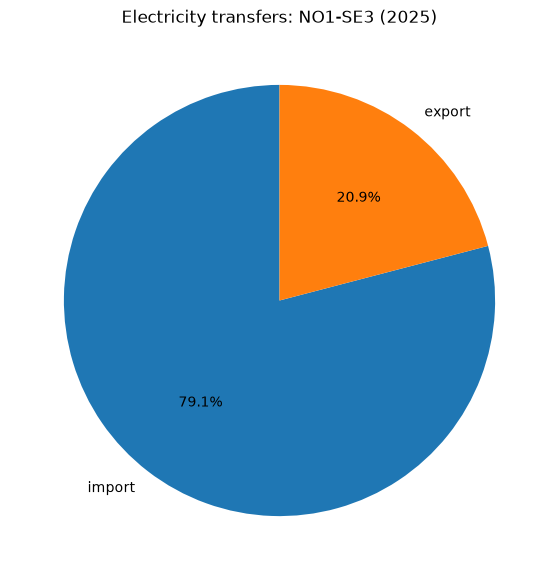

In [ ]:
# Make and display pie chart
fig, ax = plt.subplots(figsize=(7, 7))

ax.pie(
    annual_entsoe["total_mwh"],
    labels=annual_entsoe["direction"],
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title(f"Electricity transfers: {connection} ({year})")

plt.show()

Very surprising result to me. Norway imported 79% and exported 21%. Could be wrong, but I tested other connections and compared with other student's results, and they were similar. 

In [ ]:
# Extract a one month electricity transfers for the selected connection and year, separating observations by timestamp and direction.
monthly_entsoe = (
    processed_entsoe
    .filter(
        (F.col("connection") == connection) &
        (F.col("year") == year) &
        (F.col("month") == 1)
    )
    .groupBy("time", "connection", "direction")
    .agg(F.sum("mwh").alias("mwh"))
    .orderBy("time")
    .toPandas()
)

monthly_entsoe.head()

,time,connection,direction,mwh
0,2025-01-01 00:00:00,NO1-SE3,export,0.000
1,2025-01-01 00:00:00,NO1-SE3,import,1458.150
2,2025-01-01 01:00:00,NO1-SE3,export,0.000
3,2025-01-01 01:00:00,NO1-SE3,import,1650.215
4,2025-01-01 02:00:00,NO1-SE3,export,0.000


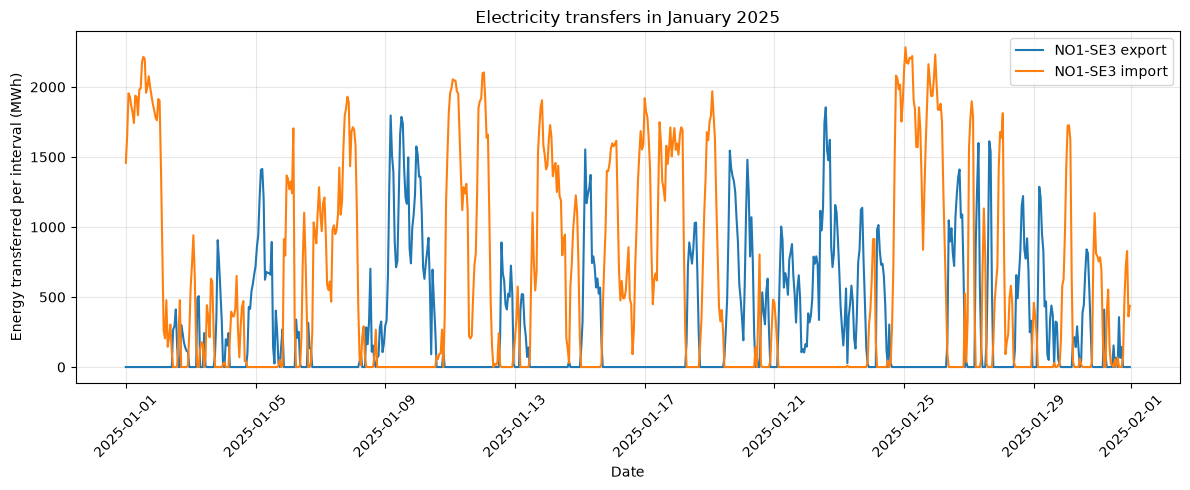

In [ ]:
# Making and plotting a graph
fig, ax = plt.subplots(figsize=(12, 5))

for (conn, direction), group in monthly_entsoe.groupby(
    ["connection", "direction"]
):
    ax.plot(
        group["time"],
        group["mwh"],
        label=f"{conn} {direction}"
    )

ax.set_title(f"Electricity transfers in January {year}")
ax.set_xlabel("Date")
ax.set_ylabel("Energy transferred per interval (MWh)")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.5 Insert to MongoDB using Spark

In [ ]:
# Connect to MongoDB Atlas using environment variables and select the database and collection for ENTSO-E data.
load_dotenv(override=True)

client = MongoClient(
    f"mongodb+srv://{os.environ['MONGODB_HOST']}/",
    username=os.environ["MONGODB_USER"],
    password=os.environ["MONGODB_PASSWORD"],
    authSource="admin",
    serverSelectionTimeoutMS=10000
)

client.admin.command("ping")

db = client["ind320"]
collection = db["entsoe_flows"]

print("Connected to MongoDB Atlas")

Connected to MongoDB Atlas


In [94]:
# Keep only the columns needed by Streamlit
mongo_entsoe = processed_entsoe.select(
    "connection",
    "direction",
    "time",
    "mwh",
    "year",
    "month"
)

# Create an index for efficient queries
collection.create_index([
    ("connection", 1),
    ("year", 1),
    ("month", 1),
    ("direction", 1),
    ("time", 1)
])

print("MongoDB index ready")

MongoDB index ready


In [ ]:
# Insert the processed ENTSO-E data into MongoDB Atlas in batches to improve efficiency and reduce memory usage.

# Define the number of documents to process per batch
BATCH_SIZE = 1000

# Initialize the list of database operations and a counter
operations = []
processed = 0

for row in mongo_entsoe.toLocalIterator():

    document = row.asDict()

    # Prepare an update operation using connection, direction, and time as identifiers
    # Existing documents are updated, while missing documents are inserted
    operations.append(
        UpdateOne(
            {
                "connection": document["connection"],
                "direction": document["direction"],
                "time": document["time"]
            },
            {"$set": document},
            upsert=True
        )
    )

    # Write the batch to MongoDB once it reaches the specified size
    if len(operations) >= BATCH_SIZE:
        collection.bulk_write(operations, ordered=False)

        processed += len(operations)
        operations = []

        # Display progress every 10000 observations
        if processed % 10000 == 0:
            print(f"Processed {processed:,} rows")

# Insert remaining documents
if operations:
    collection.bulk_write(operations, ordered=False)
    processed += len(operations)

print(f"Finished processing {processed:,} rows")

In [99]:
# Check
print("Documents in MongoDB:", collection.count_documents({}))

print("Example document:")
print(collection.find_one({}, {"_id": 0}))

Documents in MongoDB: 788910
Example document:
{'direction': 'export', 'connection': 'NO1-SE3', 'time': datetime.datetime(2024, 1, 1, 0, 0), 'month': 12, 'mwh': 0.0, 'year': 2023}


## 6. AI & Log

### 6.1 AI usage

I used OpenAI's GPT-6 as an assistant, both to set up the different softwares and to code when I was stuck.

### 6.2 Log

